# Çok Modlu Ürün Kategori Sınıflandırma — 2. Görsel Model

Bu not defterinde sadece ürün görseline bakan modeli eğittim .
**GPU gerekiyor**


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub

CIKTI = "/content/drive/MyDrive/onproje"
TOHUM = 42
tf.keras.utils.set_random_seed(TOHUM)   # tekrar üretilebilirlik için sabit tohum

print("TensorFlow sürümü:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow sürümü: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
veri_yolu = kagglehub.dataset_download("paramaggarwal/fashion-product-images-small")
GORSEL_KLASORU = f"{veri_yolu}/images"

veri = pd.read_csv(f"{CIKTI}/hazir_veri.csv", dtype={"id": str})
veri["yol"] = GORSEL_KLASORU + "/" + veri["id"] + ".jpg"

print(veri.shape)
print(veri.head(3))
print("Görsel var mı (ilk ürün):", os.path.exists(veri["yol"].iloc[0]))


Using Colab cache for faster access to the 'fashion-product-images-small' dataset.
(33142, 6)
      id                  productDisplayName                    ad_maskeli  \
0  44764  Globalite Men Black Startech Shoes  Globalite Men Black Startech   
1  19137    Lotto Men Sting II Brown Sandals      Lotto Men Sting II Brown   
2  53125          Myntra Women Green T-shirt            Myntra Women Green   

    articleType   kume                                                yol  
0  Casual Shoes  train  /kaggle/input/fashion-product-images-small/ima...  
1       Sandals  train  /kaggle/input/fashion-product-images-small/ima...  
2       Tshirts  train  /kaggle/input/fashion-product-images-small/ima...  
Görsel var mı (ilk ürün): True


In [ ]:
SINIFLAR = sorted(veri["articleType"].unique())
sinif_no = {sinif: i for i, sinif in enumerate(SINIFLAR)}
veri["etiket"] = veri["articleType"].map(sinif_no)

print(len(SINIFLAR), "sınıf")
print(sinif_no)
print(veri[["articleType", "etiket"]].head())


20 sınıf
{'Backpacks': 0, 'Belts': 1, 'Briefs': 2, 'Casual Shoes': 3, 'Flip Flops': 4, 'Formal Shoes': 5, 'Handbags': 6, 'Heels': 7, 'Jeans': 8, 'Kurtas': 9, 'Perfume and Body Mist': 10, 'Sandals': 11, 'Shirts': 12, 'Socks': 13, 'Sports Shoes': 14, 'Sunglasses': 15, 'Tops': 16, 'Tshirts': 17, 'Wallets': 18, 'Watches': 19}
    articleType  etiket
0  Casual Shoes       3
1       Sandals      11
2       Tshirts      17
3  Casual Shoes       3
4    Flip Flops       4


## 2. Görsellerin hazırlanması
Görseller 60×80 olduğu için 128×128 seçtim.

Boyut: (128, 128, 3)
Piksel aralığı: 2.46484375 - 255.0


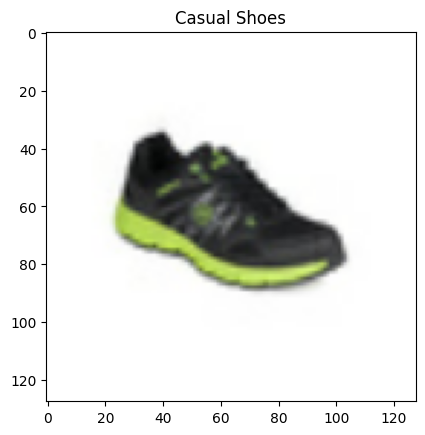

In [ ]:
BOYUT = 128

def gorsel_yukle(yol, etiket):
    g = tf.io.read_file(yol)                                         #  dosyayı oku
    g = tf.io.decode_image(g, channels=3, expand_animations=False)   # piksellere çevir
    g = tf.cast(g, tf.float32)                                       # ondalık sayıya çevir
    g = 255.0 - tf.image.resize_with_pad(255.0 - g, BOYUT, BOYUT)    # kare yap, beyaz dolgu
    # resize_with_pad siyah doldurduğu için görseli ters çevirip geri çevirdim. beyaz dolgu için
    return g, etiket

# deneme ilk ürünün görselini yükledik
ornek_g, ornek_e = gorsel_yukle(veri["yol"].iloc[0], veri["etiket"].iloc[0])
print("Boyut:", ornek_g.shape)
print("Piksel aralığı:", float(tf.reduce_min(ornek_g)), "-", float(tf.reduce_max(ornek_g)))

plt.imshow(ornek_g.numpy().astype("uint8"))
plt.title(SINIFLAR[ornek_e])
plt.show()


In [ ]:
PAKET = 64   # batch size: modele aynı anda verilen görsel sayısı

def veri_kumesi_olustur(df, karistir, onbellek=True):
    # her ürün için (görsel yolu, etiket) çiftlerinden bir liste oluşturdum
    ds = tf.data.Dataset.from_tensor_slices((df["yol"].values, df["etiket"].values))
    # her görseli oku, 128x128'e getir, beyaz dolgu ekle
    ds = ds.map(gorsel_yukle, num_parallel_calls=tf.data.AUTOTUNE)
    # görselleri bellekte tuttum hız için.
    if onbellek:
        ds = ds.cache()

    if karistir:
        ds = ds.shuffle(5000, seed=TOHUM)
    # 64'erli paketler halinde grupla; GPU çalışırken sonraki paketi hazırla
    return ds.batch(PAKET).prefetch(tf.data.AUTOTUNE)

# üç küme için ayrı boru hattıoluşturdum ki train karıştırılır, val ve test sırası korunur
train_ds = veri_kumesi_olustur(veri[veri["kume"] == "train"], karistir=True)
val_ds   = veri_kumesi_olustur(veri[veri["kume"] == "val"],   karistir=False)
test_ds  = veri_kumesi_olustur(veri[veri["kume"] == "test"],  karistir=False)

print("Paket sayısı → train:", len(train_ds), "| val:", len(val_ds), "| test:", len(test_ds))


Paket sayısı → train: 363 | val: 78 | test: 78


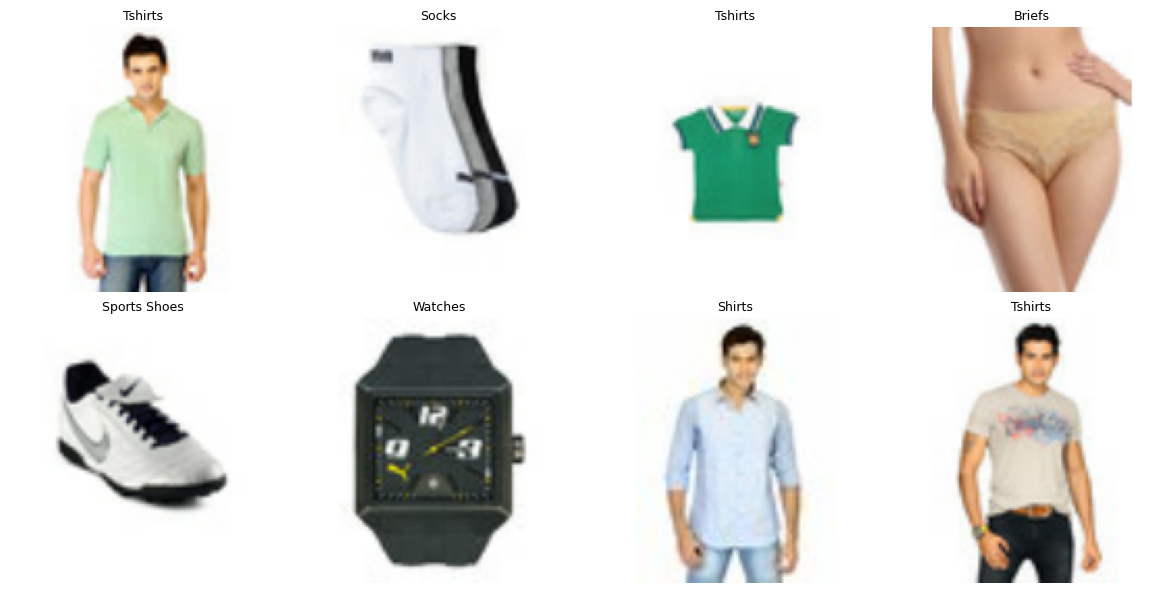

Paket boyutu: (64, 128, 128, 3)
Etiketler (ilk 8): [17 13 17  2 14 19 12 17]


In [ ]:
# eğitim boru hattından ilk paketi (64 görsel) aldım
gorseller, etiketler = next(iter(train_ds))

# ilk 8 görseli sınıf adlarıyla birlikte gösterdim
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(gorseller[i].numpy().astype("uint8"))   # ekranda göstermek için tam sayıya çevirdim
    plt.title(SINIFLAR[etiketler[i]], fontsize=9)       # etiket numarasını sınıf adına çevirdim
    plt.axis("off")
plt.tight_layout()
plt.show()

print("Paket boyutu:", gorseller.shape)
print("Etiketler (ilk 8):", etiketler[:8].numpy())


## 3. Model

ImageNet'te önceden eğitilmiş EfficientNetB0'ı gövde olarak kullandım ve üstüne 20 sınıflık
kendi sınıflandırıcımı ekledim. Eğitimde ezberlemeyi azaltmak için görselleri rastgele
çevirip döndürdüm (data augmentation yaptım).

In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

veri_artirma = keras.Sequential([
    layers.RandomFlip("horizontal"),   # görseli rastgele yatay çevir (aynalama)
    layers.RandomRotation(0.05),       # rastgele hafifçe döndür (en fazla +/- 18°)
    layers.RandomZoom(0.1),            # rastgele %10'a kadar yakınlaştır/uzaklaştır
], name="veri_artirma")

govde = keras.applications.EfficientNetB0(
    include_top=False,                 # imageNet'in 1000 sınıflık son katmanını almadım
    weights="imagenet",
    input_shape=(BOYUT, BOYUT, 3),
)
govde.trainable = False # 1. aşamada gövde donuk yalnızca sınıflandırıcı eğitilecek

# modeli birleştirdim
girdi = keras.Input(shape=(BOYUT, BOYUT, 3))
x = veri_artirma(girdi)
x = govde(x, training=False)                         # gövde tahmin modunda çalışsın
x = layers.GlobalAveragePooling2D(name="gomme")(x)   # her özellik haritasının ortalaması → 1280 sayı
x = layers.Dropout(0.3)(x)
cikti = layers.Dense(len(SINIFLAR), activation="softmax")(x)   # 20 sınıfın olasılığı

model = keras.Model(girdi, cikti)
model.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ veri_artirma (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gomme (GlobalAveragePooling2D)  │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 20)             │        25,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,075,191 (15.55 MB)

 Trainable params: 25,620 (100.08 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 4. Eğitim
### 4.1 Gövde donuk, sadece sınıflandırıcı eğitiliyor

In [ ]:
# modelin nasıl öğreneceğini ve neyi ölçeceğini belirledim
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),   # öğrenme algoritması ve öğrenme oranı
    loss="sparse_categorical_crossentropy",                # hata ölçüsü (etiketler tam sayı olduğu için "sparse")
    metrics=["accuracy"],                                  # eğitim sırasında doğruluğu da göster
)

# geri çağırmalar: eğitim sırasında her turun sonunda otomatik çalışırlar
geri_cagirmalar = [
    # val kaybı 3 tur boyunca iyileşmezse eğitimi durdurdum ve en iyi ağırlıklara geri dön
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    # val kaybı her iyileştiğinde modeli drive'a kaydet (oturum koparsa kaybolmasın)
    keras.callbacks.ModelCheckpoint(f"{CIKTI}/gorsel_asama1.keras",
                                    monitor="val_loss", save_best_only=True),
]
print("Model derlendi, geri çağırmalar hazır.")


Model derlendi, geri çağırmalar hazır.


In [ ]:
# 1. aşamada yalnızca sınıflandırıcıyı eğittim
gecmis1 = model.fit(
    train_ds,                      # eğitim verisi
    validation_data=val_ds,        # her turun sonunda val kümesinde ölç
    epochs=15,                     # en fazla 15 tur (EarlyStopping daha önce durdurabilir)
    callbacks=geri_cagirmalar,     # erken durdurma + en iyi modeli kaydetme
)

# eğitim geçmişini Drive'a kaydettim
pd.DataFrame(gecmis1.history).to_csv(f"{CIKTI}/gecmis_asama1.csv", index=False)
print("1. aşama bitti. En iyi val kaybı:", round(min(gecmis1.history["val_loss"]), 4))


Epoch 1/15
363/363 ━━━━━━━━━━━━━━━━━━━━ 107s 250ms/step - accuracy: 0.7835 - loss: 0.6836 - val_accuracy: 0.8721 - val_loss: 0.3528
Epoch 2/15
363/363 ━━━━━━━━━━━━━━━━━━━━ 24s 67ms/step - accuracy: 0.8628 - loss: 0.3846 - val_accuracy: 0.8851 - val_loss: 0.3092
Epoch 3/15
363/363 ━━━━━━━━━━━━━━━━━━━━ 24s 67ms/step - accuracy: 0.8757 - loss: 0.3421 - val_accuracy: 0.8960 - val_loss: 0.2869
Epoch 4/15
363/363 ━━━━━━━━━━━━━━━━━━━━ 25s 67ms/step - accuracy: 0.8841 - loss: 0.3180 - val_accuracy: 0.9008 - val_loss: 0.2698
Epoch 5/15
363/363 ━━━━━━━━━━━━━━━━━━━━ 25s 68ms/step - accuracy: 0.8878 - loss: 0.3071 - val_accuracy: 0.8996 - val_loss: 0.2666
Epoch 6/15
363/363 ━━━━━━━━━━━━━━━━━━━━ 25s 68ms/step - accuracy: 0.8892 - loss: 0.2979 - val_accuracy: 0.9057 - val_loss: 0.2573
Epoch 7/15
363/363 ━━━━━━━━━━━━━━━━━━━━ 25s 68ms/step - accuracy: 0.8919 - loss: 0.2883 - val_accuracy: 0.9040 - val_loss: 0.2562
Epoch 8/15
363/363 ━━━━━━━━━━━━━━━━━━━━ 24s 65ms/step - accuracy: 0.8972 - loss: 0.2840 

### 4.2 İnce ayar (son 30 katman, düşük öğrenme oranı)

In [ ]:
# gövdeyi eğitilebilir yap ama yalnızca son 30 katmanını aç
govde.trainable = True
for katman in govde.layers[:-30]:
    katman.trainable = False          # ilk katmanlar donuk kalsın (genel özellikler var)

# küçük paketlerle bozulmasınlar
for katman in govde.layers[-30:]:
    if isinstance(katman, layers.BatchNormalization):
        katman.trainable = False

# ayarları değiştirdiğimiz için modeli ÇOK KÜÇÜK öğrenme oranıyla yeniden derledim
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

egitilebilir = sum(tf.size(w).numpy() for w in model.trainable_weights)
print("Eğitilecek parametre sayısı:", egitilebilir)


Eğitilecek parametre sayısı: 1508980


In [ ]:
# 2. aşama için yeni geri çağırmalar (en iyi model ayrı bir dosyaya kaydedilsin)
geri_cagirmalar2 = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(f"{CIKTI}/gorsel_asama2.keras",
                                    monitor="val_loss", save_best_only=True),
]

# ince ayar 1. aşamanın kaldığı turdan devam etsin
ilk_tur = len(gecmis1.epoch)
gecmis2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=ilk_tur + 10,                     # en fazla 10 tur daha
    initial_epoch=ilk_tur,                   # tur numaraları 16'dan başlasın
    callbacks=geri_cagirmalar2,
)

# eğitim geçmişini Drive'a kaydettim
pd.DataFrame(gecmis2.history).to_csv(f"{CIKTI}/gecmis_asama2.csv", index=False)
print("2. aşama bitti. En iyi val kaybı:", round(min(gecmis2.history["val_loss"]), 4))


Epoch 16/25
363/363 ━━━━━━━━━━━━━━━━━━━━ 46s 81ms/step - accuracy: 0.9045 - loss: 0.2509 - val_accuracy: 0.9169 - val_loss: 0.2323
Epoch 17/25
363/363 ━━━━━━━━━━━━━━━━━━━━ 27s 74ms/step - accuracy: 0.9104 - loss: 0.2400 - val_accuracy: 0.9175 - val_loss: 0.2282
Epoch 18/25
363/363 ━━━━━━━━━━━━━━━━━━━━ 27s 75ms/step - accuracy: 0.9119 - loss: 0.2355 - val_accuracy: 0.9185 - val_loss: 0.2246
Epoch 19/25
363/363 ━━━━━━━━━━━━━━━━━━━━ 28s 76ms/step - accuracy: 0.9124 - loss: 0.2317 - val_accuracy: 0.9183 - val_loss: 0.2226
Epoch 20/25
363/363 ━━━━━━━━━━━━━━━━━━━━ 26s 72ms/step - accuracy: 0.9143 - loss: 0.2258 - val_accuracy: 0.9177 - val_loss: 0.2230
Epoch 21/25
363/363 ━━━━━━━━━━━━━━━━━━━━ 27s 74ms/step - accuracy: 0.9185 - loss: 0.2219 - val_accuracy: 0.9187 - val_loss: 0.2180
Epoch 22/25
363/363 ━━━━━━━━━━━━━━━━━━━━ 27s 74ms/step - accuracy: 0.9179 - loss: 0.2164 - val_accuracy: 0.9209 - val_loss: 0.2177
Epoch 23/25
363/363 ━━━━━━━━━━━━━━━━━━━━ 27s 75ms/step - accuracy: 0.9174 - loss: 0

Val kaybı son turda hâlâ düşüyordu, bu yüzden eğitimi 15 tur daha uzattım.

In [ ]:
# şu ana kadarki en iyi val kaybı 25. turda oldu
en_iyi_kayip = min(gecmis2.history["val_loss"])

geri_cagirmalar3 = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    # yalnızca 0.2136'dan daha iyi bir model bulunursa aynı dosyanın üstüne kaydettim
    keras.callbacks.ModelCheckpoint(f"{CIKTI}/gorsel_asama2.keras",
                                    monitor="val_loss", save_best_only=True,
                                    initial_value_threshold=en_iyi_kayip),
]

# 25. turdan devam etsin en fazla 15 tur daha
# eğer üst üst turlrd iyiye gitmezse earlystooping durduracak
ilk_tur2 = ilk_tur + len(gecmis2.epoch)
gecmis3 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=ilk_tur2 + 15,
    initial_epoch=ilk_tur2,
    callbacks=geri_cagirmalar3,
)

pd.DataFrame(gecmis3.history).to_csv(f"{CIKTI}/gecmis_asama2_devam.csv", index=False)

# bütün eğitim boyunca bulunan en iyi modeli Drive'dan geri yükledim
model = keras.models.load_model(f"{CIKTI}/gorsel_asama2.keras")
print("Devam eğitimi bitti. Bu turlardaki en iyi val kaybı:",
      round(min(gecmis3.history["val_loss"]), 4), "| önceki en iyi:", round(en_iyi_kayip, 4))


Epoch 26/40
363/363 ━━━━━━━━━━━━━━━━━━━━ 27s 75ms/step - accuracy: 0.9233 - loss: 0.2009 - val_accuracy: 0.9217 - val_loss: 0.2112
Epoch 27/40
363/363 ━━━━━━━━━━━━━━━━━━━━ 27s 75ms/step - accuracy: 0.9221 - loss: 0.2006 - val_accuracy: 0.9215 - val_loss: 0.2108
Epoch 28/40
363/363 ━━━━━━━━━━━━━━━━━━━━ 27s 75ms/step - accuracy: 0.9256 - loss: 0.1943 - val_accuracy: 0.9223 - val_loss: 0.2094
Epoch 29/40
363/363 ━━━━━━━━━━━━━━━━━━━━ 27s 75ms/step - accuracy: 0.9259 - loss: 0.1960 - val_accuracy: 0.9232 - val_loss: 0.2080
Epoch 30/40
363/363 ━━━━━━━━━━━━━━━━━━━━ 27s 74ms/step - accuracy: 0.9254 - loss: 0.1933 - val_accuracy: 0.9244 - val_loss: 0.2085
Epoch 31/40
363/363 ━━━━━━━━━━━━━━━━━━━━ 27s 74ms/step - accuracy: 0.9281 - loss: 0.1886 - val_accuracy: 0.9246 - val_loss: 0.2080
Epoch 32/40
363/363 ━━━━━━━━━━━━━━━━━━━━ 27s 74ms/step - accuracy: 0.9306 - loss: 0.1843 - val_accuracy: 0.9226 - val_loss: 0.2052
Epoch 33/40
363/363 ━━━━━━━━━━━━━━━━━━━━ 40s 72ms/step - accuracy: 0.9314 - loss: 0

### 4.3 Eğitim eğrileri

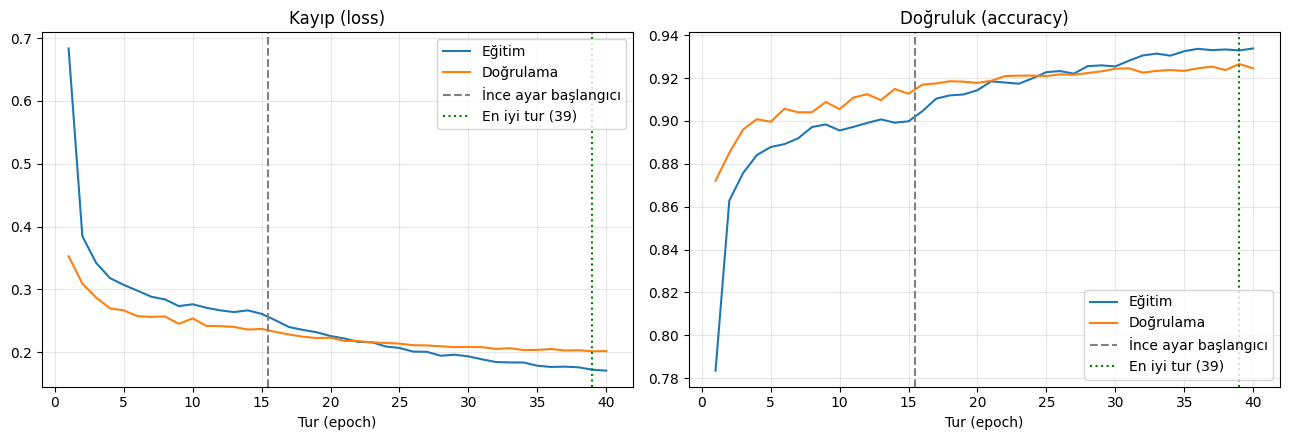

In [ ]:
# üç eğitim bölümünün geçmişini Drive'dan okuttum ve
g1 = pd.read_csv(f"{CIKTI}/gecmis_asama1.csv")          # 1. aşama: 15 tur
g2 = pd.read_csv(f"{CIKTI}/gecmis_asama2.csv")          # ince ayar: 10 tur
g3 = pd.read_csv(f"{CIKTI}/gecmis_asama2_devam.csv")    # ince ayar devamı: 15 tur
gecmis = pd.concat([g1, g2, g3], ignore_index=True)
turlar = range(1, len(gecmis) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# sol grafik: kayıp
ax1.plot(turlar, gecmis["loss"], label="Eğitim")
ax1.plot(turlar, gecmis["val_loss"], label="Doğrulama")
ax1.set_title("Kayıp (loss)")
ax1.set_xlabel("Tur (epoch)")

# sağ grafik: doğruluk
ax2.plot(turlar, gecmis["accuracy"], label="Eğitim")
ax2.plot(turlar, gecmis["val_accuracy"], label="Doğrulama")
ax2.set_title("Doğruluk (accuracy)")
ax2.set_xlabel("Tur (epoch)")

# ince ayarın başladığı yeri ve en iyi turu işaretle
en_iyi_tur = gecmis["val_loss"].idxmin() + 1
for ax in (ax1, ax2):
    ax.axvline(len(g1) + 0.5, color="gray", linestyle="--", label="İnce ayar başlangıcı")
    ax.axvline(en_iyi_tur, color="green", linestyle=":", label=f"En iyi tur ({en_iyi_tur})")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{CIKTI}/egitim_egrileri.png", dpi=150)
plt.show()


## 5. Sonuçlar

In [ ]:
from sklearn.metrics import f1_score, accuracy_score, classification_report

# val görselleri için 20 sınıfın olasılıklarını tahmin ettirdim
val_olasilik = model.predict(val_ds)
val_tahmin = val_olasilik.argmax(axis=1)          # en yüksek olasılıklı sınıfın numarası

# gerçek etiketler (val_ds karıştırılmadığı için sıra tablodakiyle aynıdır)
y_val = veri[veri["kume"] == "val"]["etiket"].values

print("Val doğruluk:", round(accuracy_score(y_val, val_tahmin), 4))
print("Val makro-F1:", round(f1_score(y_val, val_tahmin, average="macro"), 4))
print(classification_report(y_val, val_tahmin, target_names=SINIFLAR, digits=3))


78/78 ━━━━━━━━━━━━━━━━━━━━ 16s 127ms/step
Val doğruluk: 0.9266
Val makro-F1: 0.9319
                       precision    recall  f1-score   support

            Backpacks      0.946     0.972     0.959       109
                Belts      1.000     0.992     0.996       122
               Briefs      1.000     1.000     1.000       128
         Casual Shoes      0.876     0.775     0.822       427
           Flip Flops      0.858     0.927     0.891       137
         Formal Shoes      0.804     0.896     0.847        96
             Handbags      0.973     0.973     0.973       264
                Heels      0.915     0.874     0.894       198
                Jeans      1.000     0.989     0.994        91
               Kurtas      0.989     0.946     0.967       276
Perfume and Body Mist      0.968     0.989     0.978        92
              Sandals      0.854     0.822     0.838       135
               Shirts      0.946     0.952     0.949       482
                Socks      0.981 

In [ ]:
# test görselleri için olasılıkları ve tahminleri hesaplattım
test_olasilik = model.predict(test_ds)
test_tahmin = test_olasilik.argmax(axis=1)
y_test = veri[veri["kume"] == "test"]["etiket"].values

# tablo 1, 4. satır: Keras transfer öğrenme(ad kullanmıyor yalnızca görsel)
print("Test doğruluk:", round(accuracy_score(y_test, test_tahmin), 4))
print("Test makro-F1:", round(f1_score(y_test, test_tahmin, average="macro"), 4))
print(classification_report(y_test, test_tahmin, target_names=SINIFLAR, digits=3))


78/78 ━━━━━━━━━━━━━━━━━━━━ 19s 237ms/step
Test doğruluk: 0.9204
Test makro-F1: 0.9251
                       precision    recall  f1-score   support

            Backpacks      0.953     0.935     0.944       108
                Belts      1.000     0.992     0.996       122
               Briefs      0.977     1.000     0.988       127
         Casual Shoes      0.821     0.754     0.786       427
           Flip Flops      0.877     0.928     0.901       138
         Formal Shoes      0.739     0.863     0.796        95
             Handbags      0.970     0.966     0.968       264
                Heels      0.938     0.909     0.923       198
                Jeans      0.989     1.000     0.995        91
               Kurtas      0.978     0.968     0.973       277
Perfume and Body Mist      0.978     0.989     0.984        91
              Sandals      0.860     0.776     0.816       134
               Shirts      0.954     0.948     0.951       482
                Socks      1.00

## 6. Füzyon için çıktıların kaydı
Train gömmelerini önbelleksiz çıkardım çünkü önbellekle çıkarınca RAM dolup oturum çökmüştü.

In [ ]:
import json
from sklearn.metrics import f1_score, accuracy_score
from tensorflow import keras

# en iyi modeliDrive'dan yükledim
model = keras.models.load_model(f"{CIKTI}/gorsel_asama2.keras")

# val ve test olasılıklarını yeniden hesapladım ve sonuçları kontrol etttim
val_olasilik  = model.predict(val_ds)
test_olasilik = model.predict(test_ds)
y_val  = veri[veri["kume"] == "val"]["etiket"].values
y_test = veri[veri["kume"] == "test"]["etiket"].values
print("Val  makro-F1:", round(f1_score(y_val,  val_olasilik.argmax(1),  average="macro"), 4))
print("Test makro-F1:", round(f1_score(y_test, test_olasilik.argmax(1), average="macro"), 4))

np.save(f"{CIKTI}/gorsel_olasilik_val.npy", val_olasilik)
np.save(f"{CIKTI}/gorsel_olasilik_test.npy", test_olasilik)


gomme_modeli = keras.Model(model.input, model.get_layer("gomme").output)

# train verisi sıra id'lerle eşleşsin diye karıştırmadan ve bellek dolmasın diye önbelleksiz

train_sirali_ds = veri_kumesi_olustur(veri[veri["kume"] == "train"], karistir=False, onbellek=False)

for kume_adi, ds in [("train", train_sirali_ds), ("val", val_ds), ("test", test_ds)]:
    gomme = gomme_modeli.predict(ds)
    np.save(f"{CIKTI}/gorsel_gomme_{kume_adi}.npy", gomme)
    veri[veri["kume"] == kume_adi]["id"].to_csv(f"{CIKTI}/id_sirasi_{kume_adi}.csv", index=False)
    print(kume_adi, "gömme boyutu:", gomme.shape)

# sınf sırasını kaydet
with open(f"{CIKTI}/siniflar.json", "w") as f:
    json.dump(SINIFLAR, f)

print("Bütün çıktılar Drive'a kaydedildi.")


78/78 ━━━━━━━━━━━━━━━━━━━━ 20s 150ms/step
78/78 ━━━━━━━━━━━━━━━━━━━━ 9s 115ms/step
Val  makro-F1: 0.9319
Test makro-F1: 0.9251
363/363 ━━━━━━━━━━━━━━━━━━━━ 52s 135ms/step
train gömme boyutu: (23199, 1280)
78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step
val gömme boyutu: (4971, 1280)
78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step
test gömme boyutu: (4972, 1280)
Bütün çıktılar Drive'a kaydedildi.
